# Telco Customer Churn Classification

This notebook implements the five classifiers required by the assignment using the same dataset and the same stratified 80:20 train-test split. The estimator definitions are imported from the five Python files in the model/ folder.


In [3]:
from pathlib import Path
import os, sys

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "model").is_dir():
    candidates = [Path("/content/Telco_Churn_Assignment_Corrected"), Path("/content")]
    PROJECT_DIR = next((p for p in candidates if (p / "model").is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Could not find the project folder containing model/. Extract the ZIP and open this notebook from that folder.")
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))
print("Project folder:", PROJECT_DIR)
print("Dataset:", PROJECT_DIR / "test_data.csv")

Project folder: /content
Dataset: /content/test_data.csv


## 1. Import libraries and the five model modules

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef
)

# These imports make use of all five separate model files in model/.
from model.logistic_regression import build_model as build_logistic_regression
from model.decision_tree import build_model as build_decision_tree
from model.knn import build_model as build_knn
from model.gaussian_naive_bayes import build_model as build_gaussian_naive_bayes
from model.random_forest import build_model as build_random_forest

RANDOM_STATE = 42

## 2. Load the dataset and inspect its structure

In [5]:
data = pd.read_csv(PROJECT_DIR / "test_data.csv")
print("Dataset structure:", data.shape)
display(data.head())
print("\nColumn data types:")
display(data.dtypes)
print("\nMissing values before handling:")
display(data.isna().sum().sort_values(ascending=False))
print("\nExtract duplicate rows:", data.duplicated().sum())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column data types:


,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Missing values before handling:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Exact duplicate rows: 0


## 3. Dataset and target examination

The target is Churn (Yes means the customer churned). customerID is an identifier rather than a predictive feature, so it is excluded from model inputs. TotalCharges is converted to numeric; empty strings become missing values and are handled by the training-fitted imputer.

In [6]:
data = data.drop_duplicates().copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

print("Target distribution:")
display(data["Churn"].value_counts().rename("Count").to_frame())
display((data["Churn"].value_counts(normalize=True) * 100).round(2).rename("Percentage").to_frame())

y = data["Churn"].map({"No": 0, "Yes": 1})
X = data.drop(columns=["Churn", "customerID"])

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Total predictor features:", X.shape[1])

Target distribution:


,Count
Churn,
No,5174
Yes,1869


,Percentage
Churn,
No,73.46
Yes,26.54


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Total predictor features: 19


## 4. Train-test split and preprocessing

In [7]:
# 80:20 split, stratified to preserve the class distribution, fixed seed.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessing, numeric_features),
    ("categorical", categorical_preprocessing, categorical_features)
])

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training class proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())
print("Test class proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion").to_frame())

Training rows: 5634 | Test rows: 1409
Training class proportions:


,Proportion
Churn,
0,0.734647
1,0.265353


Test class proportions:


,Proportion
Churn,
0,0.734564
1,0.265436


Preprocessing safeguards: missing numeric values are replaced by the median; missing categorical values by the most frequent category; categorical values are one-hot encoded; numeric values are standardized. The preprocessing steps are inside each Pipeline, so their parameters are learned only from the training data and then applied to the test data.

## 5. Build, train and evaluate all five required classifiers

In [8]:
model_builders = {
    "Logistic Regression": build_logistic_regression,
    "Decision Tree": build_decision_tree,
    "KNN": build_knn,
    "Naive Bayes": build_gaussian_naive_bayes,
    "Random Forest": build_random_forest
}

trained_pipelines = {}
result_rows = []

for model_name, build_model in model_builders.items():
    classifier = build_model(random_state=RANDOM_STATE)
    model_pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])
    model_pipeline.fit(X_train, y_train)

    predictions = model_pipeline.predict(X_test)
    probabilities = model_pipeline.predict_proba(X_test)[:, 1]

    result_rows.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "AUC": roc_auc_score(y_test, probabilities),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "MCC": matthews_corrcoef(y_test, predictions)
    })
    trained_pipelines[model_name] = model_pipeline

results = pd.DataFrame(result_rows)
display(results.round(4))

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8055,0.8419,0.6572,0.5588,0.6040,0.4790
1,Decision Tree,0.7289,0.6573,0.4896,0.5053,0.4974,0.3119
2,KNN,0.7637,0.7895,0.5527,0.5749,0.5636,0.4018
3,Naive Bayes,0.6948,0.8074,0.4589,0.8369,0.5928,0.4245
4,Random Forest,0.7786,0.8171,0.6062,0.4733,0.5315,0.3945


## 6. Graph representation of all six evaluation metrics

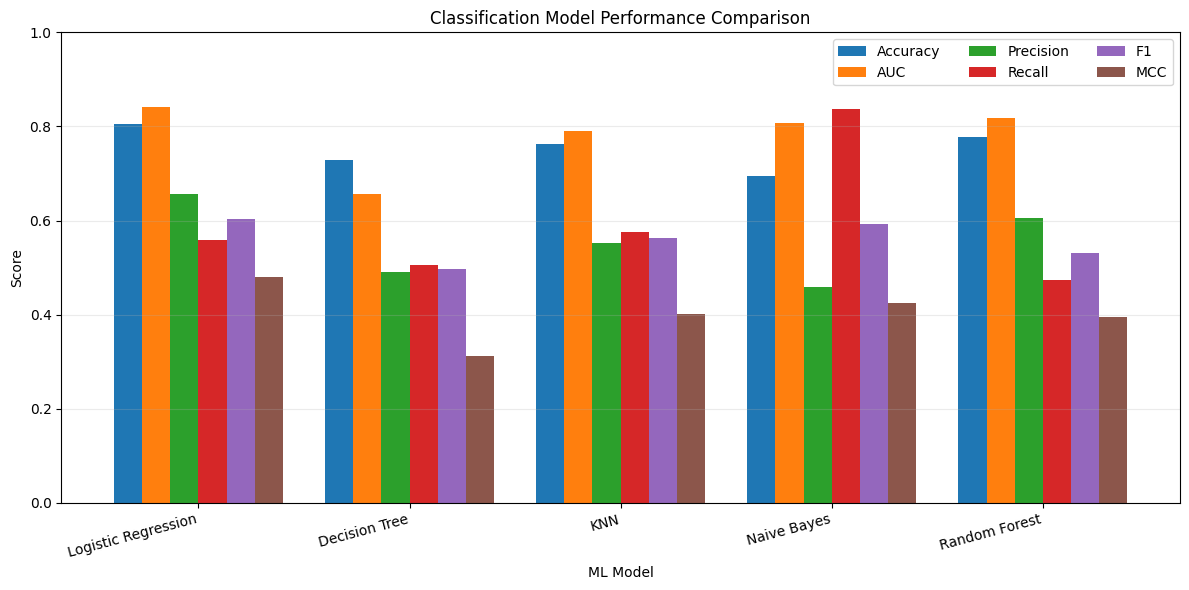

In [9]:
metric_names = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
ax = results.set_index("ML Model Name")[metric_names].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1), width=0.8
)
ax.set_title("Classification Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("ML Model")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.legend(ncol=3)
plt.tight_layout()
plt.show()

## 7. Observations and overall winner

In [10]:
for _, row in results.iterrows():
    print(
        f"{row['ML Model Name']}: Accuracy={row['Accuracy']:.4f}, "
        f"AUC={row['AUC']:.4f}, Precision={row['Precision']:.4f}, "
        f"Recall={row['Recall']:.4f}, F1={row['F1']:.4f}, MCC={row['MCC']:.4f}"
    )

print("\\nHighest value by metric:")
display(results.set_index("ML Model Name")[metric_names].idxmax().rename("Best model").to_frame())

# Overall winner is selected by the highest F1 score; this balances precision and recall.
winner_row = results.loc[results["F1"].idxmax()]
print(
    f"\\nOverall winner by F1 score: {winner_row['ML Model Name']} "
    f"(F1={winner_row['F1']:.4f})."
)

Logistic Regression: Accuracy=0.8055, AUC=0.8419, Precision=0.6572, Recall=0.5588, F1=0.6040, MCC=0.4790
Decision Tree: Accuracy=0.7289, AUC=0.6573, Precision=0.4896, Recall=0.5053, F1=0.4974, MCC=0.3119
KNN: Accuracy=0.7637, AUC=0.7895, Precision=0.5527, Recall=0.5749, F1=0.5636, MCC=0.4018
Naive Bayes: Accuracy=0.6948, AUC=0.8074, Precision=0.4589, Recall=0.8369, F1=0.5928, MCC=0.4245
Random Forest: Accuracy=0.7786, AUC=0.8171, Precision=0.6062, Recall=0.4733, F1=0.5315, MCC=0.3945
\nHighest value by metric:


,Best model
Accuracy,Logistic Regression
AUC,Logistic Regression
Precision,Logistic Regression
Recall,Naive Bayes
F1,Logistic Regression
MCC,Logistic Regression


\nOverall winner by F1 score: Logistic Regression (F1=0.6040).
